In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from typing import Iterable, Optional, Sequence, Tuple

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from parse_eval_logs import (
    agg_rs_results,
)
from tqdm import tqdm

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "pgf.rcfonts": False,
})


LOGS_DIR = Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/")

# Logs loading

In [3]:
padding_length = ["0", "1000","5000","10000", "50000","100000","200000", "800000"]
padding_types = [ "before","after", "around"]
task_types = ["benign", "harm"]

# Grok-4-fast random

In [4]:
# [harm/benign][mix/benign][after/before/around][gpt-4.1-nano][padding_length]
grok_rand_pad = {task_type: {pad_type: {"grok-4-fast": {}} for pad_type in ["before","after"]} for task_type in task_types}
print(grok_rand_pad)

for task_type in ["harm", "benign"]:
        for pad_type in tqdm(["before","after"], desc=f"Processing {task_type}"):
            for pad_len in padding_length:
                try:
                    if pad_len == "0":
                        grok_rand_pad[task_type][pad_type]["grok-4-fast"][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/grok-4-fast_multi_task_padding/mix/0_before_with_task_instructed/test_hint_det_prompt")
                    else:
                        dir_name = f"{pad_len}_{pad_type}"          
                        grok_rand_pad[task_type][pad_type]["grok-4-fast"][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/grok-4-fast_random_padding/{dir_name}/test_hint_det_prompt")
                except Exception as e:
                    print(e, f"{task_type}/random_padding/{dir_name}/test_hint_det_prompt")

{'benign': {'before': {'grok-4-fast': {}}, 'after': {'grok-4-fast': {}}}, 'harm': {'before': {'grok-4-fast': {}}, 'after': {'grok-4-fast': {}}}}


Processing harm:  50%|█████     | 1/2 [00:20<00:20, 20.51s/it]

[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/grok-4-fast_random_padding/800000_before/test_hint_det_prompt' harm/random_padding/800000_before/test_hint_det_prompt


Processing harm: 100%|██████████| 2/2 [00:40<00:00, 20.42s/it]


[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/grok-4-fast_random_padding/800000_after/test_hint_det_prompt' harm/random_padding/800000_after/test_hint_det_prompt


Processing benign:  50%|█████     | 1/2 [00:22<00:22, 22.69s/it]

[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/grok-4-fast_random_padding/800000_before/test_hint_det_prompt' benign/random_padding/800000_before/test_hint_det_prompt


Processing benign: 100%|██████████| 2/2 [00:43<00:00, 21.93s/it]

[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/grok-4-fast_random_padding/800000_after/test_hint_det_prompt' benign/random_padding/800000_after/test_hint_det_prompt


# Sonoma random

In [5]:
sonoma_model_types = ["sonoma-dusk-alpha", "sonoma-sky-alpha"]

# sonoma[harm/benign][after/before/around][sky/dusk][padding_length]
sonoma_random_paddings = {
    task_type: {
        pad_type: {k: {}
            for k in sonoma_model_types}
        for pad_type in padding_types}
    for task_type in task_types
}
print(sonoma_random_paddings)

for task_type in task_types:
    for pad_type in tqdm(padding_types, desc=f"Processing {task_type}"):
        for model in sonoma_model_types:
            for pad_len in padding_length:
                if pad_len == "0":
                    dir_name = f"{pad_len}_after" # for 0 padding we have common run        
                else:
                    dir_name = f"{pad_len}_{pad_type}"
                
                try:
                    sonoma_random_paddings[task_type][pad_type][model][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_random_padding/{dir_name}/{model}/test_hint_det_prompt")
                except Exception as e:
                    print(f"Error: {f'{task_type}/sonoma_random_padding/{dir_name}/{model}/test_hint_det_prompt'}")

# sonoma_harm_rand_pad = sonoma_random_paddings["harm"]
# sonoma_benign_rand_pad = sonoma_random_paddings["benign"]

{'benign': {'before': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'after': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'around': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}}, 'harm': {'before': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'after': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}, 'around': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}}}


Processing benign:   0%|          | 0/3 [00:00<?, ?it/s]

Error: benign/sonoma_random_padding/5000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/10000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/100000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/800000_before/sonoma-dusk-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/5000_before/sonoma-sky-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/10000_before/sonoma-sky-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/100000_before/sonoma-sky-alpha/test_hint_det_prompt


Processing benign:  33%|███▎      | 1/3 [00:42<01:25, 42.68s/it]

Error: benign/sonoma_random_padding/800000_before/sonoma-sky-alpha/test_hint_det_prompt
Error: benign/sonoma_random_padding/800000_after/sonoma-dusk-alpha/test_hint_det_prompt


Processing benign:  67%|██████▋   | 2/3 [01:43<00:53, 53.17s/it]

... (7 outputs left out)

Processing harm:  67%|██████▋   | 2/3 [01:31<00:47, 47.46s/it]

Error: harm/sonoma_random_padding/800000_after/sonoma-sky-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/5000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/10000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/100000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/800000_around/sonoma-dusk-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/5000_around/sonoma-sky-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/10000_around/sonoma-sky-alpha/test_hint_det_prompt
Error: harm/sonoma_random_padding/100000_around/sonoma-sky-alpha/test_hint_det_prompt


Processing harm: 100%|██████████| 3/3 [02:14<00:00, 44.76s/it]

Error: harm/sonoma_random_padding/800000_around/sonoma-sky-alpha/test_hint_det_prompt


In [6]:
# [harm/benign][after/before/around][sky/dusk][padding_length]
ds31_random_paddings = {task_type: { pad_type: {"deepseekv3.1": {}} for pad_type in padding_types} for task_type in task_types}
print(ds31_random_paddings)

token_alignment = {
    0:0,
    1_000: 1760,
    5_000: 8800,
    10_000: 17600,
    50_000: 88000,
    72_000: 126700
}

for task_type in task_types:
    for pad_type in tqdm(["after"], desc=f"Processing {task_type}"):
        for pad_len in ["0", "1000","5000","10000", "50000"]:
            try:
                ds31_random_paddings[task_type][pad_type]["deepseekv3.1"][token_alignment[int(pad_len)]] = agg_rs_results(LOGS_DIR / f"{task_type}/deepseek-chat-v3.1_random_padding/{pad_len}_{pad_type}/test_hint_det_prompt")
            except Exception as e:
                print(f"{task_type}/random_padding/{dir_name}/deepseekv3.1/test_hint_det_prompt")

{'benign': {'before': {'deepseekv3.1': {}}, 'after': {'deepseekv3.1': {}}, 'around': {'deepseekv3.1': {}}}, 'harm': {'before': {'deepseekv3.1': {}}, 'after': {'deepseekv3.1': {}}, 'around': {'deepseekv3.1': {}}}}


Processing harm: 100%|██████████| 1/1 [00:08<00:00,  8.06s/it]


In [7]:
# [harm/benign][after/before/around][sky/dusk][padding_length]
gpt_nano_random_paddings = {task_type: { pad_type: {"gpt-4.1-nano": {}} for pad_type in padding_types} for task_type in task_types}
print(gpt_nano_random_paddings)

for task_type in task_types:
    for pad_type in tqdm(padding_types, desc=f"Processing {task_type}"):
        for pad_len in padding_length:
            if pad_len == "800000":
                continue
            if pad_len == "0":
                dir_name = f"{pad_len}_after" # for 0 padding we have common run        
            else:
                dir_name = f"{pad_len}_{pad_type}"
            try:
                gpt_nano_random_paddings[task_type][pad_type]["gpt-4.1-nano"][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")
            except Exception as e:
                print(f"{task_type}/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")

{'benign': {'before': {'gpt-4.1-nano': {}}, 'after': {'gpt-4.1-nano': {}}, 'around': {'gpt-4.1-nano': {}}}, 'harm': {'before': {'gpt-4.1-nano': {}}, 'after': {'gpt-4.1-nano': {}}, 'around': {'gpt-4.1-nano': {}}}}


Processing benign:   0%|          | 0/3 [00:00<?, ?it/s]

benign/random_padding/1000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/5000_before/gpt_4.1_nano/test_hint_det_prompt


Processing benign:  33%|███▎      | 1/3 [00:07<00:14,  7.48s/it]

benign/random_padding/50000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/100000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/200000_before/gpt_4.1_nano/test_hint_det_prompt
benign/random_padding/50000_after/gpt_4.1_nano/test_hint_det_prompt


Processing benign:  67%|██████▋   | 2/3 [00:24<00:13, 13.14s/it]

... (5 outputs left out)

Processing harm:  33%|███▎      | 1/3 [00:22<00:44, 22.38s/it]

harm/random_padding/200000_before/gpt_4.1_nano/test_hint_det_prompt
harm/random_padding/50000_after/gpt_4.1_nano/test_hint_det_prompt


Processing harm: 100%|██████████| 3/3 [00:52<00:00, 17.58s/it]

harm/random_padding/50000_around/gpt_4.1_nano/test_hint_det_prompt
harm/random_padding/100000_around/gpt_4.1_nano/test_hint_det_prompt
harm/random_padding/200000_around/gpt_4.1_nano/test_hint_det_prompt


# multi-task

In [8]:
num_tasks2padding_len = {0:0, 5: 282, 10: 464, 30: 1617, 50: 2641}
mt_task_types = ["harm", "benign"]
mt_pad_cont_types = ["mix"]
mt_padding_types = ["around_with_task_instructed", "before_with_task_instructed", "around", "after_with_task_instructed"]
mt_padding_length = ["0","5","10","30","50"]
# [harm/benign][mix/benign][after/before/around][gpt-4.1-nano][padding_length]
gpt4_nano_mt_pad = {task_type: {pad_cont: {pad_type: {"gpt-4.1-nano": {}} for pad_type in mt_padding_types} for pad_cont in mt_pad_cont_types} for task_type in mt_task_types}
print(gpt4_nano_mt_pad)

for task_type in mt_task_types:
    for pad_cont_t in mt_pad_cont_types:
        for pad_type in tqdm(mt_padding_types, desc=f"Processing {task_type}"):
            for pad_len in mt_padding_length:
                try:
                    if pad_len == "0":
                        gpt4_nano_mt_pad[task_type][pad_cont_t][pad_type]["gpt-4.1-nano"][num_tasks2padding_len[int(pad_len)]] = agg_rs_results(LOGS_DIR / f"{task_type}/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")
                    else:
                        dir_name = f"{pad_len}_{pad_type}"            
                        gpt4_nano_mt_pad[task_type][pad_cont_t][pad_type]["gpt-4.1-nano"][num_tasks2padding_len[int(pad_len)]] = agg_rs_results(LOGS_DIR / f"{task_type}/multi_task_padding/{pad_cont_t}/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")

                except Exception as e:
                    print(e, f"{task_type}/multi_task_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")

{'harm': {'mix': {'around_with_task_instructed': {'gpt-4.1-nano': {}}, 'before_with_task_instructed': {'gpt-4.1-nano': {}}, 'around': {'gpt-4.1-nano': {}}, 'after_with_task_instructed': {'gpt-4.1-nano': {}}}}, 'benign': {'mix': {'around_with_task_instructed': {'gpt-4.1-nano': {}}, 'before_with_task_instructed': {'gpt-4.1-nano': {}}, 'around': {'gpt-4.1-nano': {}}, 'after_with_task_instructed': {'gpt-4.1-nano': {}}}}}


Processing benign:  25%|██▌       | 1/4 [00:02<00:08,  2.91s/it]

[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/5_around_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/5_around_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/10_around_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/10_around_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/30_around_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/30_around_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/50_around_with_task_instructed/gpt_4.1_nano/test_hi

Processing benign:  50%|█████     | 2/4 [00:05<00:05,  2.79s/it]

[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/5_before_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/5_before_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/10_before_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/10_before_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/30_before_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/30_before_with_task_instructed/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/50_before_with_task_instructed/gpt_4.1_nano/test_hi

Processing benign:  75%|███████▌  | 3/4 [00:08<00:02,  2.80s/it]

[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/5_around/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/5_around/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/10_around/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/10_around/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/30_around/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/30_around/gpt_4.1_nano/test_hint_det_prompt
[Errno 2] No such file or directory: '/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/mix/50_around/gpt_4.1_nano/test_hint_det_prompt' benign/multi_task_padding/50_around/gpt_4.1_nano/test_hint_det_prompt


Processing benign: 100%|██████████| 4/4 [00:16<00:00,  4.20s/it]


In [9]:
num_tasks2padding_len = {0:0, 5: 282, 10: 464, 30: 1617, 50: 2641}
mt_task_types = ["harm", "benign"]
mt_pad_cont_types = ["mix"]
mt_padding_types = ["after_with_task_instructed"]
mt_padding_length = ["0","5","10","30","50"]
# [harm/benign][mix/benign][after/before/around][gpt-4.1-nano][padding_length]
deepseek_mt_pad = {task_type: {pad_cont: {pad_type: {"deepseek-v3.1": {}} for pad_type in mt_padding_types} for pad_cont in mt_pad_cont_types} for task_type in mt_task_types}
print(deepseek_mt_pad)

for task_type in mt_task_types:
    for pad_cont_t in mt_pad_cont_types:
        for pad_type in tqdm(mt_padding_types, desc=f"Processing {task_type}"):
            for pad_len in mt_padding_length:
                try:
                    if pad_len == "0":
                        deepseek_mt_pad[task_type][pad_cont_t][pad_type]["deepseek-v3.1"][num_tasks2padding_len[int(pad_len)]] = agg_rs_results(LOGS_DIR / f"{task_type}/deepseek-chat-v3.1_random_padding/0_after/test_hint_det_prompt")
                    else:
                        dir_name = f"{pad_len}_{pad_type}"                
                        deepseek_mt_pad[task_type][pad_cont_t][pad_type]["deepseek-v3.1"][num_tasks2padding_len[int(pad_len)] * 1.76] = agg_rs_results(LOGS_DIR / f"{task_type}/deepseekv31_multi_task_padding/{pad_cont_t}/{dir_name}/test_hint_det_prompt")
                except Exception as e:
                    print(e, f"{task_type}/multi_task_padding/{dir_name}/test_hint_det_prompt")

{'harm': {'mix': {'after_with_task_instructed': {'deepseek-v3.1': {}}}}, 'benign': {'mix': {'after_with_task_instructed': {'deepseek-v3.1': {}}}}}


Processing benign: 100%|██████████| 1/1 [00:06<00:00,  6.59s/it]


In [10]:
num_tasks2padding_len = {0:0, 5: 282, 10: 464, 30: 1617, 50: 2641}
mt_task_types = ["harm", "benign"]
mt_pad_cont_types = ["mix"]
mt_padding_types = ["after_with_task_instructed", "before_with_task_instructed"]
mt_padding_length = ["0","5","10","30","50"]
# [harm/benign][mix/benign][after/before/around][gpt-4.1-nano][padding_length]
grok_mt_pad = {task_type: {pad_cont: {pad_type: {"grok-4-fast": {}} for pad_type in mt_padding_types} for pad_cont in mt_pad_cont_types} for task_type in mt_task_types}
print(grok_mt_pad)

for task_type in mt_task_types:
    for pad_cont_t in mt_pad_cont_types:
        for pad_type in tqdm(mt_padding_types, desc=f"Processing {task_type}"):
            for pad_len in mt_padding_length:
                try:
                    if pad_len == "0":
                        grok_mt_pad[task_type][pad_cont_t][pad_type]["grok-4-fast"][num_tasks2padding_len[int(pad_len)]] = agg_rs_results(LOGS_DIR / f"{task_type}/grok-4-fast_multi_task_padding/mix/0_before_with_task_instructed/test_hint_det_prompt")
                    else:
                        dir_name = f"{pad_len}_{pad_type}"          
                        grok_mt_pad[task_type][pad_cont_t][pad_type]["grok-4-fast"][num_tasks2padding_len[int(pad_len)]] = agg_rs_results(LOGS_DIR / f"{task_type}/grok-4-fast_multi_task_padding/{pad_cont_t}/{dir_name}/test_hint_det_prompt")
                except Exception as e:
                    print(e, f"{task_type}/multi_task_padding/{dir_name}/test_hint_det_prompt")

{'harm': {'mix': {'after_with_task_instructed': {'grok-4-fast': {}}, 'before_with_task_instructed': {'grok-4-fast': {}}}}, 'benign': {'mix': {'after_with_task_instructed': {'grok-4-fast': {}}, 'before_with_task_instructed': {'grok-4-fast': {}}}}}


Processing benign: 100%|██████████| 2/2 [00:08<00:00,  4.40s/it]


## non-relevant

In [11]:
irrel_task_types = ["harm","benign"]
irrel_padding_types = ["after"]
irrel_model_types = ["sonoma-dusk-alpha", "sonoma-sky-alpha"]
irrel_padding_length = ["0", "1000","5000","10000", "50000","100000","200000","500000","800000"]

# [harm/benign][after/before/around][gpt-4.1-nano][padding_length]
sonoma_irrel_pad = {task_type: {pad_type: {model: {} for model in irrel_model_types} for pad_type in irrel_padding_types} for task_type in irrel_task_types}
print(sonoma_irrel_pad)

for task_type in irrel_task_types:
    for pad_type in irrel_padding_types:
        for model in irrel_model_types:
            for pad_len in irrel_padding_length:
                try:
                    sonoma_irrel_pad[task_type][pad_type][model][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/sonoma_non_relevant_padding/{pad_len}_{pad_type}/{model}/test_hint_det_prompt")
                except Exception as e:
                    print(f"{task_type}/sonoma_non_relevant_padding/{pad_len}_{pad_type}/{model}/test_hint_det_prompt")

{'harm': {'after': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}}, 'benign': {'after': {'sonoma-dusk-alpha': {}, 'sonoma-sky-alpha': {}}}}
harm/sonoma_non_relevant_padding/500000_after/sonoma-dusk-alpha/test_hint_det_prompt
harm/sonoma_non_relevant_padding/500000_after/sonoma-sky-alpha/test_hint_det_prompt
harm/sonoma_non_relevant_padding/800000_after/sonoma-sky-alpha/test_hint_det_prompt
benign/sonoma_non_relevant_padding/800000_after/sonoma-dusk-alpha/test_hint_det_prompt


In [12]:
irrel_task_types = ["harm","benign"]
irrel_padding_types = ["after"]

# [harm/benign][after/before/around][gpt-4.1-nano][padding_length]
gpt41_nano_irrel_pad = {task_type: {pad_type: {model: {} for model in ["gpt-4.1-nano-2025-04"]} for pad_type in irrel_padding_types} for task_type in irrel_task_types}
print(gpt41_nano_irrel_pad)

for task_type in irrel_task_types:
    for pad_type in irrel_padding_types:
        for model in ["gpt-4.1-nano-2025-04"]:
            for pad_len in  ["0", "1000","5000","10000", "50000","100000"]:
                try:
                    if pad_len == "0":
                        gpt41_nano_irrel_pad[task_type][pad_type][model][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt")
                    else:
                        gpt41_nano_irrel_pad[task_type][pad_type][model][int(pad_len)] = agg_rs_results(LOGS_DIR / f"{task_type}/non_relevant/{pad_len}_{pad_type}/{model}/test_hint_det_prompt")
                except Exception as e:
                    print(f"{task_type}/non_relevant_padding/{pad_len}_{pad_type}/{model}/test_hint_det_prompt")

{'harm': {'after': {'gpt-4.1-nano-2025-04': {}}}, 'benign': {'after': {'gpt-4.1-nano-2025-04': {}}}}


## Plot

In [32]:
from typing import Sequence, Tuple, Optional, Hashable
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb, to_hex
import colorsys
from matplotlib.lines import Line2D

# Each point: (x, [rep1, rep2, ...])
Point = Tuple[float, Sequence[float]]
Series = Sequence[Point]

def _adjust_lightness(color: str, delta_l: float) -> str:
    r, g, b = to_rgb(color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    l = max(0.0, min(1.0, l + delta_l))
    r2, g2, b2 = colorsys.hls_to_rgb(h, l, s)
    return to_hex((r2, g2, b2))

def plot_xy_mean_se(
    *series: Series,
    labels: Optional[Sequence[str]] = None,
    # --- category controls ---
    categories: Optional[Sequence[Hashable]] = None,
    category_colors: Optional[Sequence[str]] = None,
    category_linestyles: Optional[Sequence[str]] = None,
    category_filled_markers: Optional[Sequence[bool]] = None,
    intra_lightness_steps: Sequence[float] = (0.0, 0.18, 0.32, 0.45),
    # --- figure / layout size controls ---
    figsize: Optional[Tuple[float, float]] = None,  # inches (w, h). None -> use rcParams default
    figure_scale: float = 1.0,                      # multiplies width & height
    dpi: Optional[int] = None,                      # e.g., 150/200 for PNG; ignored by vector PDF
    constrained_layout: bool = False,               # True: let MPL auto-manage layout
    tight_layout: bool = True,                      # If not using constrained_layout, apply fig.tight_layout
    tight_layout_pad: float = 0.5,                  # padding (inches) for fig.tight_layout
    # --- general plot controls ---
    title: str = "",
    xlabel: str = "x",
    ylabel: str = "y",
    logx: bool = False,
    symlog_linthresh: float = 1.0,
    marker: str = "o",
    linewidth: float = 2.0,
    markersize: float = 6.0,
    capsize: float = 3.0,
    # --- legend controls ---
    legend_bbox_to_anchor=(0.02, 1),
    legend_columnspacing: float=0.6,
    show_series_legend: bool = True,
    legend_markerscale: float =0.9,
    legend_handletextpad:float=0.4,
    show_category_legend: bool = True,
    legend_ncol: int = 3,
    series_legend_loc: str = "upper left",
    category_legend_loc: str = "lower right",
    series_legend_title: Optional[str] = None,
    category_legend_title: str = "Categories",
    figure_file_name: str = "figure",
):
    """
    Plot (x, [y...]) as mean ± SE with category-aware styling.

    New: controls for figure size (figsize), scaling (figure_scale), DPI, and layout (tight/constrained).
    """
    if not series:
        raise ValueError("Provide at least one series of (x, [values]) points.")

    n_series = len(series)
    if categories is None:
        categories = ["category-1"] * n_series
    if len(categories) != n_series:
        raise ValueError("Length of 'categories' must match number of series.")

    # Determine category order by first appearance
    cat_order: list[Hashable] = []
    for c in categories:
        if c not in cat_order:
            cat_order.append(c)
    n_cats = len(cat_order)

    default_cat_colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
    if category_colors is None:
        category_colors = default_cat_colors[:max(n_cats, 2)]
    elif len(category_colors) < n_cats:
        category_colors = list(category_colors)
        while len(category_colors) < n_cats:
            category_colors += category_colors

    if category_linestyles is None:
        category_linestyles = ["-", "--", "-.", ":"]
    if category_filled_markers is None:
        category_filled_markers = [True, False, True, False]

    cat_to_indices = {c: [] for c in cat_order}
    for idx, c in enumerate(categories):
        cat_to_indices[c].append(idx)

    # ---- figure sizing ----
    if figsize is None:
        # Use current Matplotlib default if not provided
        base_w, base_h = plt.rcParams.get("figure.figsize", (6.4, 4.8))
    else:
        base_w, base_h = figsize
    eff_figsize = (base_w * figure_scale, base_h * figure_scale)

    fig, ax = plt.subplots(figsize=eff_figsize, dpi=dpi, constrained_layout=constrained_layout)

    # Plot each series with category styling and within-category lightness variation
    for cat_idx, cat in enumerate(cat_order):
        base_color = category_colors[cat_idx % len(category_colors)]
        ls = category_linestyles[cat_idx % len(category_linestyles)]
        filled = bool(category_filled_markers[cat_idx % len(category_filled_markers)])

        members = cat_to_indices[cat]
        for j, s_idx in enumerate(members):
            s = series[s_idx]
            if not s:
                continue

            s_sorted = sorted(s, key=lambda p: p[0])
            xs, means, ses = [], [], []
            for x, vals in s_sorted:
                v = np.asarray(list(vals), dtype=float)
                if v.size == 0:
                    continue
                m = float(np.mean(v))
                se = float(np.std(v, ddof=1) / np.sqrt(v.size)) if v.size > 1 else 0.0
                xs.append(x); means.append(m); ses.append(se)

            delta_l = intra_lightness_steps[j % len(intra_lightness_steps)]
            series_color = _adjust_lightness(base_color, delta_l)

            label = (labels[s_idx] if labels and s_idx < len(labels) else f"series {s_idx+1}")

            if filled:
                mfc = series_color
                mec = series_color
            else:
                mfc = "white"
                mec = series_color

            ax.errorbar(
                xs, means, yerr=ses,
                fmt=marker,
                linestyle=ls,
                linewidth=linewidth,
                markersize=markersize,
                capsize=capsize,
                color=series_color,
                markerfacecolor=mfc,
                markeredgecolor=mec,
                markeredgewidth=1.5,
                ecolor=series_color,
                label=label,
            )

    if logx:
        ax.set_xscale("symlog", linthresh=symlog_linthresh)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", linestyle="--", alpha=0.5)

    # ---- Legends: keep BOTH by adding the first as an artist, then creating the second ----
    series_leg = None
    if show_series_legend:
        series_leg = ax.legend(ncol=legend_ncol, bbox_to_anchor=legend_bbox_to_anchor, loc=series_legend_loc, markerscale=legend_markerscale,handletextpad=legend_handletextpad, title=series_legend_title, columnspacing=legend_columnspacing, frameon=True)
        ax.add_artist(series_leg)

    if show_category_legend:
        cat_handles = []
        for cat_idx, cat in enumerate(cat_order):
            base_color = category_colors[cat_idx % len(category_colors)]
            ls = category_linestyles[cat_idx % len(category_linestyles)]
            filled = bool(category_filled_markers[cat_idx % len(category_filled_markers)])
            demo_color = _adjust_lightness(base_color, intra_lightness_steps[0])
            mfc = demo_color if filled else "white"
            mec = demo_color
            cat_handles.append(Line2D(
                [0], [0],
                color=demo_color, linestyle=ls, linewidth=linewidth,
                marker=marker, markersize=markersize,
                markerfacecolor=mfc, markeredgecolor=mec, markeredgewidth=1.5,
                label=str(cat),
            ))
        ax.legend(ncol=legend_ncol, handles=cat_handles, title=category_legend_title,
                  loc=category_legend_loc, markerscale=legend_markerscale, handletextpad=legend_handletextpad,columnspacing=legend_columnspacing,frameon=True, bbox_to_anchor=legend_bbox_to_anchor)

    # Tight layout only if not using constrained_layout (which already manages it)
    if tight_layout and not constrained_layout:
        fig.tight_layout(pad=tight_layout_pad)

    fig.savefig(f"paper_plots/{figure_file_name}.pdf", bbox_inches="tight")
    return fig, ax



# Figure 2a: score degradation

In [73]:
metrics_2a = [
    # random padding    
    ("grok-4-fast R", [(k, v.metrics_overall_agg["avg_score"]) for k, v in grok_rand_pad["harm"]["after"]["grok-4-fast"].items()]),    
    ("grok-4-fast MT", [(k, v.metrics_overall_agg["avg_score"]) for k, v in grok_mt_pad["harm"]["mix"]["after_with_task_instructed"]["grok-4-fast"].items()]),

    ("gpt-4.1-nano R", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano MT", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["after_with_task_instructed"]["gpt-4.1-nano"].items()]),

    # multi-task padding
    ("deepseek-v3.1 R", [(k, v.metrics_overall_agg["avg_score"]) for k, v in ds31_random_paddings["harm"]["after"]["deepseekv3.1"].items()]),
    ("deepseek-v3.1 MT", [(k, v.metrics_overall_agg["avg_score"]) for k, v in deepseek_mt_pad["harm"]["mix"]["after_with_task_instructed"]["deepseek-v3.1"].items()]),
]

# metrics_2a = [
#     # random padding    
#     ("grok-4-fast", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["after"]["sonoma-dusk-alpha"].items()]),    
#     ("gpt-4.1-nano R", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["after"]["gpt-4.1-nano"].items()]),
#     ("deepseek-v3.1 R", [(k, v.metrics_overall_agg["avg_score"]) for k, v in ds31_random_paddings["benign"]["after"]["deepseekv3.1"].items()]),
#     # multi-task padding
#     ("gpt-4.1-nano MT", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["benign"]["mix"]["after_with_task_instructed"]["gpt-4.1-nano"].items()]),
#     ("deepseek-v3.1 MT", [(k, v.metrics_overall_agg["avg_score"]) for k, v in deepseek_mt_pad["benign"]["mix"]["after_with_task_instructed"]["deepseek-v3.1"].items()]),
#     # ("grok-4-fast", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["after_with_task_instructed"]["grok-4-fast"].items()]),
# ]

In [74]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 14.5, 
    "axes.labelsize": 20.5, "axes.titlesize": 17.5,
    "xtick.labelsize": 18, "ytick.labelsize": 18.5,
    "legend.fontsize": 13,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


(<Figure size 720x550 with 1 Axes>,
 <Axes: xlabel='padding size in tokens', ylabel='Score'>)

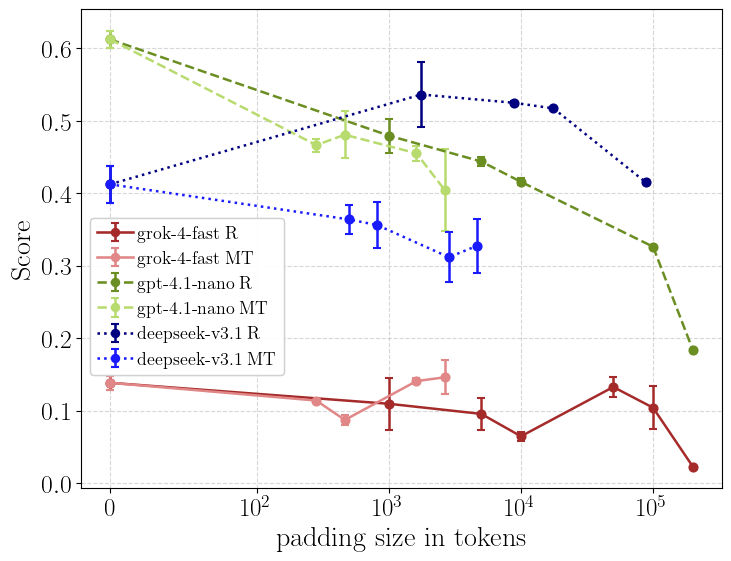

In [77]:
plot_xy_mean_se(
    *[m for _,m in metrics_2a],
    labels=[l for l,_ in metrics_2a],
    categories= ["grok-4-fast","grok-4-fast", "gpt-4.1-nano", "gpt-4.1-nano", "deepseek-v3.1","deepseek-v3.1"],
    category_colors=["brown", "olivedrab", "navy"],
    category_linestyles=["-", "--", ":"],
    intra_lightness_steps=[0.0, 0.3],
    category_filled_markers=[True, True, True],
    series_legend_loc="center left",
    logx=True,
    xlabel="padding size in tokens",
    ylabel="Score",
    legend_ncol=1,
    symlog_linthresh=100,
    show_category_legend = False,
    figsize=(7.2, 5.5),   # single-column width
    linewidth=1.8,
    markersize=5.8,
    capsize=3.2,
    tight_layout=True,
    tight_layout_pad=0.2,
    legend_bbox_to_anchor=(0, 0.4),
    legend_columnspacing=0.2,
    legend_markerscale=0.9,
    legend_handletextpad=0.2,
    figure_file_name="figure_2a"
)

# Figure 2b: refusals

In [52]:
# sonoma
metrics_2b = [
    # random padding    
    ("grok-4-fast R", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in grok_rand_pad["harm"]["before"]["grok-4-fast"].items()]),    
    ("grok-4-fast MT", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in grok_mt_pad["harm"]["mix"]["after_with_task_instructed"]["grok-4-fast"].items()]),
   
    ("gpt-4.1-nano R", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano MT", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["after_with_task_instructed"]["gpt-4.1-nano"].items()]),

    ("deepseek-v3.1 R", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in ds31_random_paddings["harm"]["after"]["deepseekv3.1"].items()]),
    ("deepseek-v3.1 MT", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in deepseek_mt_pad["harm"]["mix"]["after_with_task_instructed"]["deepseek-v3.1"].items()]),
    
    # ("gpt-4.1-nano NR", [(k, v.metrics_overall_agg["avg_refusals"]) for k, v in gpt41_nano_irrel_pad["harm"]["after"]["gpt-4.1-nano-2025-04"].items()]),


    # multi-task padding
]

(<Figure size 720x550 with 1 Axes>,
 <Axes: xlabel='padding size in tokens', ylabel='Avg refusals'>)

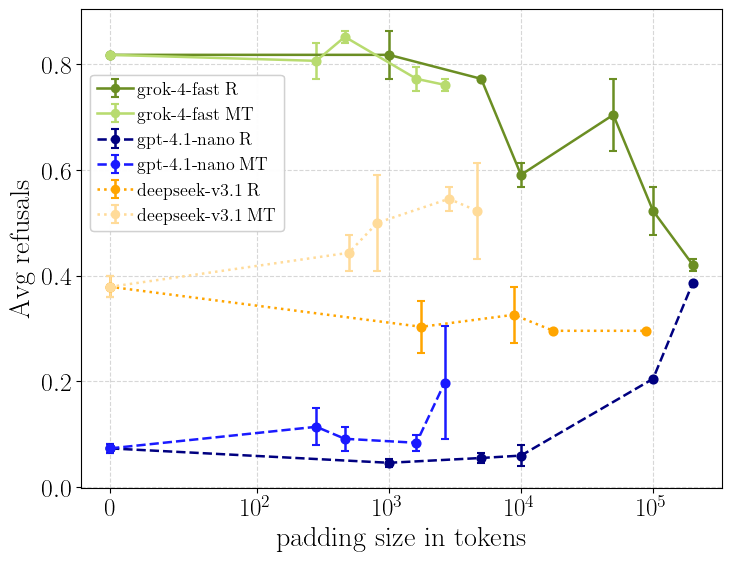

In [56]:
plot_xy_mean_se(
    *[m for _,m in metrics_2b],
    labels=[l for l,_ in metrics_2b],
    categories=["grok-4-fast","grok-4-fast","gpt-4.1-nano","gpt-4.1-nano","deepseek-v3.1","deepseek-v3.1"],  # two categories
    category_colors=["olivedrab", "navy", "orange"],
    category_linestyles=["-", "--", ":"],
    intra_lightness_steps=[0.0,0.3],
    category_filled_markers=[True, True, True],
    series_legend_loc="center left",
    category_legend_loc="lower left",
    logx=True,
    symlog_linthresh=100,
    xlabel="padding size in tokens",
    ylabel="Avg refusals",
    legend_ncol=1,
    show_category_legend = False,
    figsize=(7.2, 5.5),   # single-column width
    linewidth=1.8,
    markersize=5.8,
    capsize=3.2,
    tight_layout=True,
    tight_layout_pad=0.2,
    legend_bbox_to_anchor=(0, 0.7),
    legend_columnspacing=0.2,
    legend_markerscale=0.9,
    legend_handletextpad=0.2,
    figure_file_name="figure_2b"
)

# Figure 3: before and after padding

In [86]:
metrics_fig3_score = [
    ## gpt-4.1-nano
        ("R before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["harm"]["before"]["gpt-4.1-nano"].items()]),
        ("R after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
        ("MT before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["before_with_task_instructed"]["gpt-4.1-nano"].items()]),
        ("MT after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["after_with_task_instructed"]["gpt-4.1-nano"].items()]),

    ## grok-4-fast
        # ("R before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in grok_rand_pad["harm"]["before"]["grok-4-fast"].items()]),
        # ("MT before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in grok_mt_pad["harm"]["mix"]["before_with_task_instructed"]["grok-4-fast"].items()]),
        # ("R after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in grok_rand_pad["harm"]["after"]["grok-4-fast"].items()]),
        # ("MT after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in grok_mt_pad["harm"]["mix"]["after_with_task_instructed"]["grok-4-fast"].items()]),
]


# metrics_fig3_score = [
#     ## gpt-4.1-nano
#     ("gpt-4.1-nano R", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["before"]["gpt-4.1-nano"].items()]),
#     ("gpt-4.1-nano MT", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["before_with_task_instructed"]["gpt-4.1-nano"].items()]),
#     ("gpt-4.1-nano R after", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
#     ("gpt-4.1-nano MT after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["after_with_task_instructed"]["gpt-4.1-nano"].items()]),
# ]


(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='padding size in tokens', ylabel='Score'>)

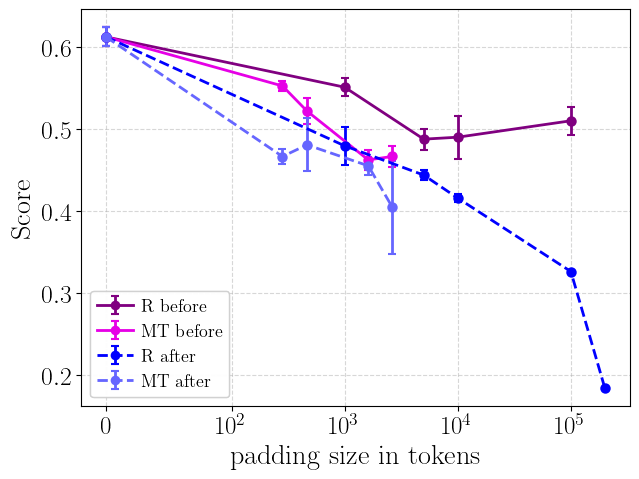

In [92]:
plot_xy_mean_se(
    *[m for _,m in metrics_fig3_score],
    labels=[l for l,_ in metrics_fig3_score],
    categories=["before","after", "before","after"],  # two categories
    category_colors=["purple", "blue"],
    category_linestyles=["-", "--"],
    intra_lightness_steps=[0.0, 0.2],
    category_filled_markers=[True, True],
    symlog_linthresh=100,
    series_legend_loc="lower left",
    category_legend_loc="upper right",
    logx=True,
    xlabel="padding size in tokens",
    ylabel="Score",
    legend_ncol=1,
    legend_bbox_to_anchor=(0.0, 0.0),
    show_category_legend = False,
    figure_file_name="figure3"
)

# Figure Multi-task appendix

# Figure 1 complete

In [ ]:
metrics_score = [
    # random padding
    
    ## sonoma
    # ("sonoma dusk rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("sonoma sky rand before",[(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-sky-alpha"].items()]),
    ("grok-4-fast rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-dusk-alpha"].items()]),
    # ("sonoma sky rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["after"]["sonoma-sky-alpha"].items()]),
    # ("sonoma dusk rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("sonoma sky rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["harm"]["before"]["sonoma-sky-alpha"].items()]),
    # ("benign sonoma dusk rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("benign sonoma sky rand before",[(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-sky-alpha"].items()]),
    # ("benign sonoma dusk rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["after"]["sonoma-dusk-alpha"].items()]),
    # ("benign sonoma sky rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["after"]["sonoma-sky-alpha"].items()]),
    # ("benign sonoma dusk rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-dusk-alpha"].items()]),
    # ("benign sonoma sky rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_random_paddings["benign"]["before"]["sonoma-sky-alpha"].items()]),
    
    ## gpt-4.1-nano
    ("gpt-4.1-nano", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["after"]["gpt-4.1-nano"].items()]),
    # ("gpt-4.1-nano rand before", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["before"]["gpt-4.1-nano"].items()]),
    # ("gpt-4.1-nano rand around", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in gpt_nano_random_paddings["harm"]["around"]["gpt-4.1-nano"].items()]),
    # ("benign gpt-4.1-nano rand after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["after"]["gpt-4.1-nano"].items()]),
    # ("benign gpt-4.1-nano rand before", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["before"]["gpt-4.1-nano"].items()]),
    # ("benign gpt-4.1-nano rand around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt_nano_random_paddings["benign"]["around"]["gpt-4.1-nano"].items()]),
    
    ## deepseek v3.1

    ("deepseekv3.1", [(k, v.metrics_overall_agg["avg_score_non_refusals"]) for k, v in ds31_random_paddings["harm"]["after"]["deepseekv3.1"].items()]),
    


    # multi-task padding
    
    ## gpt-4.1-nano
    # ("gpt-4.1-nano MT MIX around_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["around_with_task_instructed"]["gpt-4.1-nano"].items()]),
    # ("gpt-4.1-nano MT MIX around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["around"]["gpt-4.1-nano"].items()]),
    # ("gpt-4.1-nano MT MIX before_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["before_with_task_instructed"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["after_with_task_instructed"]["gpt-4.1-nano"].items()]),
    
    # ("gpt-4.1-nano MT BENIGN around_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["benign"]["around_with_task_instructed"]["gpt-4.1-nano"].items()]),
    # ("gpt-4.1-nano MT BENIGN around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["benign"]["around"]["gpt-4.1-nano"].items()]),
    # ("gpt-4.1-nano MT BENIGN before_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["benign"]["before_with_task_instructed"]["gpt-4.1-nano"].items()]),
    
    ## deepseek v3.1
    ("deepseek-v3.1", [(k, v.metrics_overall_agg["avg_score"]) for k, v in deepseek_mt_pad["harm"]["mix"]["after_with_task_instructed"]["deepseek-v3.1"].items()]),


    ## Grok-4-fast    
    ("grok-4-fast", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["after_with_task_instructed"]["grok-4-fast"].items()]),


    # non-relevant padding
    ## sonoma
    # ("harm sonoma-dusk irrel pad after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_irrel_pad["harm"]["after"]["sonoma-dusk-alpha"].items()]),
    # ("benign sonoma-dusk irrel pad after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_irrel_pad["benign"]["after"]["sonoma-dusk-alpha"].items()]),
    # ("harm sonoma-sky irrel pad after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_irrel_pad["harm"]["after"]["sonoma-sky-alpha"].items()]),
    # ("benign sonoma-sky irrel pad after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in sonoma_irrel_pad["benign"]["after"]["sonoma-sky-alpha"].items()]),
    ## gpt-4.1-nano
    # ("harm gpt4.1nano irrel pad after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt41_nano_irrel_pad["harm"]["after"]["gpt-4.1-nano-2025-04"].items()]),
    # ("benign gpt4.1nano irrel pad after", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt41_nano_irrel_pad["benign"]["after"]["gpt-4.1-nano-2025-04"].items()]),
]

In [23]:
mt_metrics_score = [
    # random padding
    ## sonoma
    ## gpt-4.1-nano
    # multi-task padding
    ## gpt-4.1-nano
    ("gpt-4.1-nano MT MIX around_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["around_with_task_instructed"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano MT MIX around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["around"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano MT MIX before_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["mix"]["before_with_task_instructed"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano MT BENIGN around_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["benign"]["around_with_task_instructed"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano MT BENIGN around", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["benign"]["around"]["gpt-4.1-nano"].items()]),
    ("gpt-4.1-nano MT BENIGN before_wi", [(k, v.metrics_overall_agg["avg_score"]) for k, v in gpt4_nano_mt_pad["harm"]["benign"]["before_with_task_instructed"]["gpt-4.1-nano"].items()]),

]

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='padding size in tokens', ylabel='score'>)

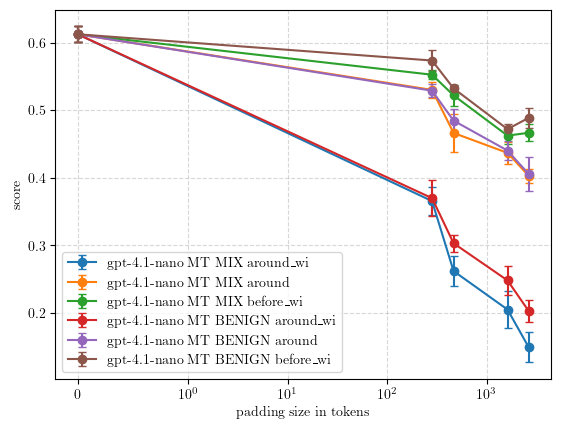

In [25]:
plot_xy_mean_se(
    *[m for _,m in mt_metrics_score],
    labels=[l for l,_ in mt_metrics_score],
    logx=True,
    xlabel="padding size in tokens",
    ylabel="score",
    save_figure = True,
    figure_file_name="figure_appendix_mt_score"
)